# 02b — Information seeking in a T-maze

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/02b_active_inference_vs_rl.ipynb)

## Why this notebook

An informative action can improve a later decision even when it earns no immediate reward. The T-maze makes that idea concrete: a cue identifies the rewarding arm, but reaching an arm after reading it takes a detour through the center. A planner that knows the task model can evaluate that detour before its first trial. A Q-learner starts with zero action values and must learn them from experience.

There are three comparison agents: a known-model planner with an information-gain term, the same kind of planner with that term set to zero, and a tabular learner. The reward-only planner is essential. It demonstrates that reward maximization can already favor the cue because information improves future reward. Cue seeking is therefore not a unique behavioral signature of an epistemic objective.

### Learning goals

1. Trace a legal route through the maze and identify when the hidden context becomes known.
2. Separate an immediate information bonus from the instrumental value of information.
3. Explain the role of prior model knowledge, training budget and evaluation policy.
4. Read learning curves without interpreting unequal starting knowledge as a general ranking of theories.

Section numbers in the background readings refer to the [August background paper](https://github.com/arvidl/brains-to-models/blob/main/paper/background/august-perspective.pdf). For the current paper and 30-minute presentation, use the [paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) and the [slide-to-resource guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md).


## Concepts and two reading paths

<details open>
<summary><strong>For clinicians and neuroscientists</strong></summary>

**Hidden context** specifies which arm is rewarding. The agent initially cannot observe it. A **belief** is a probability assigned to each context; the default prior is equally split. Visiting the cue makes that belief informative in the deterministic task.

**Planning** uses a supplied transition and observation model to imagine possible outcomes. **Learning action values** estimates how useful actions are from experienced rewards. These are different resources. The clinical analogy is deciding whether a test can improve a subsequent choice: the test itself need not cure anything to be useful. The numerical maze does not represent test harms, clinical uncertainty or patient outcomes.

**Exploration** in the learner is $\varepsilon$-greedy: some actions are sampled randomly. **Greedy evaluation** sets that exploration rate to zero after training. Performance during exploratory training need not equal the performance of the learned policy.

</details>

<details>
<summary><strong>For mathematically inclined readers</strong></summary>

The simplified belief planner combines expected utility and information gain. For belief $b(c)$ about context $c$, an observation's expected information is

$$I(c;o)=H[b(c)]-\sum_o p(o)H[b(c\mid o)].$$

The planner averages possible observations and conditions subsequent choices on them. It uses a finite-horizon utility/information calculation, a teaching approximation rather than a full expected-free-energy implementation.

The learner's state includes remaining moves, location and remembered cue. The action-specific update is

$$Q(s,a)\leftarrow Q(s,a)+\alpha\{r+\gamma\max_{a'}Q(s',a')-Q(s,a)\}.$$

At a terminal arm there is no future-value term. Including remaining moves makes the finite-horizon decision state explicit. Updating only the selected action prevents an observed reward from incorrectly changing all alternatives at once.

</details>


### Run in Colab or locally

Click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells in order (**Runtime → Run all**). The setup downloads the shared code and figure references from the public repository, installs the small numerical dependencies, and prints the checkout and Python version. It excludes the large presentation. No GPU, API key, patient data or Google Drive mount is needed.

Locally, use the environment in the [repository instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select its Python kernel in Cursor or JupyterLab. The setup finds the repository and sets the working directory to `code/notebooks`, so exercise paths such as `%load ../solutions/...py` work in either environment.

Re-running setup reuses the existing checkout; it does not discard your runtime edits or pull new code automatically. For a fresh Colab checkout after repository updates, use **Runtime → Disconnect and delete runtime**, then reconnect and run again. Use **File → Save a copy in Drive** to retain notebook edits, and download generated files separately before the runtime ends. Saved output is a preview; rerunning produces the evidence for your session.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.tmaze import (
    LOC_NAMES,
    render_paper_figure,
    run_experiment,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)

Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2
repo root: CHECKOUT
seed: 7


## The maze

Center connects to cue, left arm and right arm. Staying put is allowed. From cue, return through center before entering an arm. An arm ends the trial and supplies one reward or punishment. Center → cue → center → arm takes three moves.

**Before running.** Trace each legal move before reading the returns. A cue cannot teleport the agent directly into an arm: it must pass through the center. Once an arm is entered, the trial ends. The same hidden-context sequence is used for the agents, so inspect differences in their information and update rules before attributing differences to context sampling.


In [2]:
traces = run_experiment(n_trials=400, n_steps=3, seed=SEED)
for name, trials in traces.items():
    first = trials[0]
    cue_rate = sum(t.visited_cue_first for t in trials) / len(trials)
    mean_return = sum(sum(t.rewards) for t in trials) / len(trials)
    print(name, 'first route:', [LOC_NAMES[i] for i in first.locations])
    print('  exploratory training / known-model run:',
          'cue-first', round(cue_rate, 3), 'mean return', round(mean_return, 3))


aif first route: ['center', 'cue', 'center', 'right']
  exploratory training / known-model run: cue-first 1.0 mean return 1.0
ql first route: ['center', 'right']
  exploratory training / known-model run: cue-first 0.242 mean return 0.055
reward_only first route: ['center', 'cue', 'center', 'right']
  exploratory training / known-model run: cue-first 1.0 mean return 1.0


## Comparison figure

All agents encounter the same context sequence. The reward-only known-model planner controls for the instrumental value of information. Q-learning starts with zero values; its learning curve is not a comparison under equal prior knowledge.


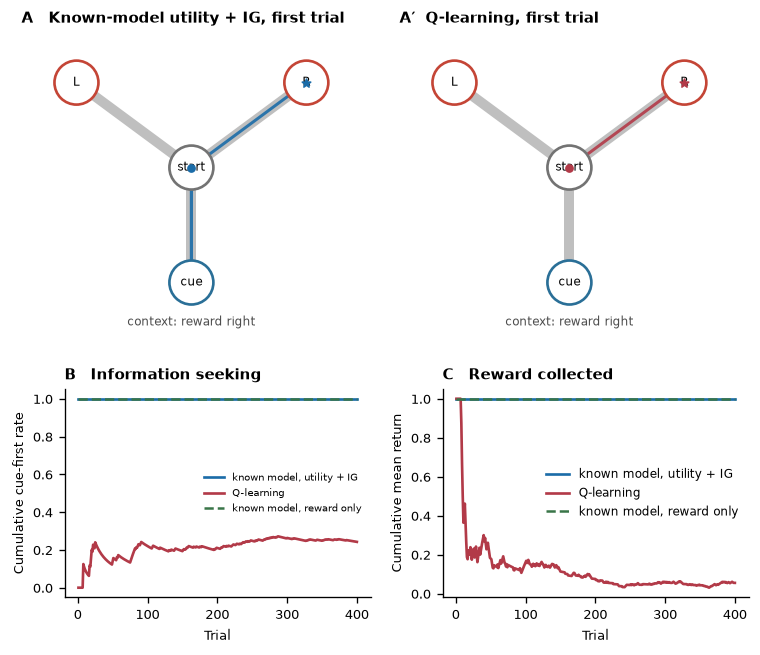

wrote CHECKOUT/paper/figures/tmaze_aif_vs_ql.pdf
wrote CHECKOUT/paper/figures/tmaze_aif_vs_ql.png
wrote CHECKOUT/paper/figures/tmaze_aif_vs_ql.pdf


In [3]:
fig = render_paper_figure(traces)
plt.show()
out = write_figure(traces, root / "paper" / "figures")
print("wrote", out)

## Learning and evaluation budgets

The 400-trial plot shows early learning with exploration enabled. Give the Q-learner 5,000 training trials, then disable exploration and evaluate on a fresh balanced context sequence. Report this separately from its exploratory training return.

**Before running.** The Q table is trained first, then its parameters are held fixed during evaluation. Setting epsilon to zero removes random exploration; `learn=False` prevents the evaluation cases from becoming more training. Predict how this differs from reporting the last few exploratory training trials. The balanced context list also makes accidental side imbalance an avoidable explanation.


In [4]:
import numpy as np
from brainsmodels.tmaze import TMaze, QLearningAgent, run_trial_ql
learner = QLearningAgent(seed=SEED)
training_maze = TMaze(seed=SEED)
for context in np.random.default_rng(SEED).integers(0, 2, 5000):
    run_trial_ql(training_maze, learner, context=int(context))
learner.epsilon = 0.0
contexts = np.tile([0, 1], 100)
np.random.default_rng(SEED + 1).shuffle(contexts)
evaluation_maze = TMaze(seed=SEED + 2)
evaluation = [run_trial_ql(evaluation_maze, learner,
                          context=int(context), learn=False)
              for context in contexts]
print('Greedy evaluation after 5,000 training trials')
print('Cue-first rate:', np.mean([t.visited_cue_first for t in evaluation]))
print('Mean return:', np.mean([sum(t.rewards) for t in evaluation]))


Greedy evaluation after 5,000 training trials
Cue-first rate: 1.0
Mean return: 1.0


## What the controls teach

With the default three-move budget, the legal informative route is center → cue → center → indicated arm. Arms are terminal and provide at most one reward. With payoffs $+1$ and $-1$, guessing an arm under an equal prior has expected return zero. A perfect cue followed by the correct arm gives return one. There is no movement cost or discount penalty in this default comparison, so a reward-only planner can prefer the informative route.

This reasoning is independent of an extra information bonus. Removing that bonus does not remove the information's influence on later reward. A genuine diagnostic experiment for an intrinsic information preference would need a setting where future reward, action costs and knowledge are controlled. The present maze illustrates the distinction; it does not supply that experiment.

### Read the figures as learning records

The first-route panel shows one trajectory, not an average. The cue-first curve reports whether the cue preceded either arm; merely visiting a cue after committing would not count. Mean return measures realized reward. All agents face the same context sequence in the comparison, which removes one avoidable source of variation but does not equalize their prior knowledge.

The first run covers 400 trials. The later cell gives the Q-learner 5,000 training trials, freezes learning, removes random exploration and evaluates on 200 balanced contexts. The difference between these records separates learning time and exploration from what the trained table can achieve. It prevents an early performance gap from being mistaken for an inability to learn the cue's usefulness.

### Try a discriminating intervention

Shorten the available horizon until the cue route cannot reach reward. Then consider adding a cost to movement or making the cue unreliable. Predict how each change affects expected return before editing the implementation. Change one assumption at a time and ensure both model-based agents are given the same new assumptions. Their use of a supplied model should remain visible in the report.

The comparison is relevant to information-seeking behavior and to the distinction between model-based planning and model-free value learning. It does not establish that cortex minimizes this score, that reinforcement learning cannot value information, or that one algorithm captures clinical decision-making. The central lesson is to identify which term, knowledge source and horizon explain an observed policy.


### Exercises

1. **Information gain and planning horizon.** Compare the known-model planners with and without information gain at horizons 1 and 3. Can future reward alone justify a cue visit?

<!-- solution-box: 02b_1_drop_the_epistemic_term.py -->
<details>
<summary><strong>Show solution</strong> — Information gain and planning horizon</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/02b_1_drop_the_epistemic_term.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.tmaze import ActiveInferenceAgent, TMaze, run_trial_aif
for horizon in (1, 3):
    for weight in (0., 1.):
        agent = ActiveInferenceAgent(horizon=horizon, epistemic_weight=weight)
        trace = run_trial_aif(TMaze(seed=SEED), agent, context=1)
        print(f"horizon={horizon}, IG weight={weight}: {trace.locations}, return={sum(trace.rewards):+.1f}")
print("The three-move reward-only planner can value information instrumentally. Both planners know the model.")
```

</details>
<!-- /solution-box -->


2. **A noisy cue.** The environment and the agent both default to `cue_accuracy=1`. Set both to $0.6$ and compare cue-first rate and mean reward over 40 trials against the perfect-cue agent. When does “go to the cue first” stop being worth the step?

<!-- solution-box: 02b_2_a_noisy_cue.py -->
<details>
<summary><strong>Show solution</strong> — A noisy cue</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/02b_2_a_noisy_cue.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.tmaze import ActiveInferenceAgent, TMaze, run_trial_aif
def score(acc, n=40):
    env = TMaze(cue_accuracy=acc, seed=SEED)
    agent = ActiveInferenceAgent(cue_accuracy=acc)
    cues, rews = [], []
    for _ in range(n):
        tr = run_trial_aif(env, agent, n_steps=3)
        cues.append(tr.visited_cue_first)
        rews.append(sum(tr.rewards))
    return float(np.mean(cues)), float(np.mean(rews))

for acc in (1.0, 0.6, 0.5):
    cue, rew = score(acc)
    print(f"cue accuracy {acc:.1f}  cue-first {cue:.2f}  mean return {rew:+.2f}")
print('At accuracy 0.5 the cue carries no information about context. Report the selected route and return at each accuracy. Test value also depends on costs, available actions and the remaining horizon.')
```

</details>
<!-- /solution-box -->


3. **Prior knowledge and learned action values.** Compare the three agents on matched contexts for 400 trials. Then inspect the Q-learner’s start-state action values. Which prior-knowledge difference prevents attributing an early gap to the objective alone?

<!-- solution-box: 02b_3_ql_needs_the_stumble.py -->
<details>
<summary><strong>Show solution</strong> — Prior knowledge and learned action values</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/02b_3_ql_needs_the_stumble.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.tmaze import CENTER, QLearningAgent, TMaze, run_trial_ql, run_experiment
traces = run_experiment(n_trials=400, seed=SEED)
for name, trials in traces.items():
    print(name, "cue-first", np.mean([t.visited_cue_first for t in trials]), "return", np.mean([sum(t.rewards) for t in trials]))
agent = QLearningAgent(seed=SEED)
env = TMaze(seed=SEED)
for context in np.random.default_rng(SEED).integers(0, 2, 400):
    run_trial_ql(env, agent, context=int(context))
print("Learned Q(center, unknown):", agent.Q[agent.max_steps, CENTER, 0])
print("The learner begins without the transition and observation model supplied to both planners.")
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. What does each agent know before the first trial?

2. Can a reward-only planner value visiting the cue?

3. What changes when the planning horizon is shortened?

4. How should the Q-update and cue-first metric be checked?

5. What conclusions about organisms follow from this comparison?


### Further reading

These references provide background for the models and discussion. Distinguish primary experiments, reviews and commentary when using them as evidence. Section references follow the August background paper.

1. **Friston, K. J., Daunizeau, J., and Kiebel, S. J. (2009).** [*Reinforcement learning or active inference?*](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0006421). *PLoS ONE* 4(7), e6421.
2. **Sajid, N., Ball, P. J., Parr, T., and Friston, K. J. (2021).** [*Active inference: demystified and compared*](https://arxiv.org/abs/1909.10863). *Neural Computation* 33(3), 674–712. arXiv:1909.10863.
3. **Friston, K., et al. (2017).** [*Active inference: A process theory*](https://doi.org/10.1162/NECO_a_00912). *Neural Computation* 29(1), 1–49.
4. **Levine, S. (2018).** [*Reinforcement learning and control as probabilistic inference: Tutorial and review*](https://arxiv.org/abs/1805.00909). arXiv:1805.00909.
5. **Heins, C., et al. (2022).** [*pymdp: A Python library for active inference in discrete state spaces*](https://doi.org/10.21105/joss.04098). *Journal of Open Source Software* 7(73), 4098.
6. **Friston, K. (2010).** [*The free-energy principle: a unified brain theory?*](https://www.fil.ion.ucl.ac.uk/~karl/The%20free-energy%20principle%20A%20unified%20brain%20theory.pdf). *Nature Reviews Neuroscience* 11, 127–138. Author PDF.
